<a href="https://colab.research.google.com/github/eileen795/MSSP-6070/blob/main/assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. import modules and data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

# Public GitHub RAW link for the CSV used in this assignment
DATA_URL = (
    'https://raw.githubusercontent.com/eileen795/MSSP-6070/'
    'main/Assignments/assignment2/InternetSales%20%283%29.csv'
)
df = pd.read_csv(DATA_URL, encoding='latin1', low_memory=False)
print('Dataset shape:', df.shape)
print('\nColumn names:\n', df.columns.tolist())
display(df.head())

Dataset shape: (60398, 60)

Column names:
 ['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode', 'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title', 'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate', 'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome', 'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation', 'SpanishEducation', 'FrenchEducation', 'EnglishOccupation', 'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag', 'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone', 'DateFirstPurchase', 'CommuteDistance', 'ProductKey', 'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey', 'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey', 'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber', 'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct', 'DiscountAmount', 'ProductStandardCost', 'TotalProductCost', 'SalesAmount', 'TaxAmt', 'Freight', 'CarrierTrackingNumber', 'Customer

,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


## 2. Prepare data and create product categories

In [3]:
# Clean essential variables used by the analysis
df['OrderDate'] = pd.to_datetime(df['OrderDate'], format='%m/%d/%Y', errors='coerce')
for col in ['SalesAmount', 'UnitPrice', 'OrderQuantity', 'YearlyIncome', 'HouseOwnerFlag']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.dropna(subset=[
    'OrderDate', 'SalesAmount', 'UnitPrice', 'OrderQuantity',
    'YearlyIncome', 'HouseOwnerFlag', 'CustomerKey',
    'EnglishCountryRegionName', 'EnglishProductName', 'Gender'
]).copy()
df['Year'] = df['OrderDate'].dt.year

# The CSV has no ProductCategory column, so infer the category from product names.
def get_product_category(name):
    name = str(name)
    if name.startswith(('Mountain-', 'Road-', 'Touring-')):
        return 'Bikes'
    clothing_words = ('Jersey', 'Shorts', 'Gloves', 'Vest', 'Socks', 'Cap')
    if any(word in name for word in clothing_words):
        return 'Clothing'
    return 'Accessories'

df['ProductCategory'] = df['EnglishProductName'].apply(get_product_category)

print('Missing values in analysis columns:')
print(df[['OrderDate', 'SalesAmount', 'YearlyIncome', 'HouseOwnerFlag']].isna().sum())
print('\nSales years:', sorted(df['Year'].unique()))
print('\nProduct categories:')
print(df['ProductCategory'].value_counts())
print('\nRows after cleaning:', len(df))

Missing values in analysis columns:
OrderDate         0
SalesAmount       0
YearlyIncome      0
HouseOwnerFlag    0
dtype: int64

Sales years: [np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014)]

Product categories:
ProductCategory
Accessories    36092
Bikes          15205
Clothing        9101
Name: count, dtype: int64

Rows after cleaning: 60398


## 3. Question 1 — Annual Internet sales by country/region

Q1. Internet sales by year and country/region (USD):


EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
Year,,,,,,
2010,20909.78,3578.27,3399.99,0.00,699.10,14833.90
2011,2563732.25,571571.80,410845.33,520500.16,550591.22,2458285.17
2012,2128407.46,307604.52,648065.54,608657.98,712700.96,1437048.73
2013,4339443.38,1085632.65,1578511.80,1761876.36,2124007.29,5462078.86
2014,8507.72,9457.62,3195.06,3277.83,3713.64,17542.85


Total sales by country/region:


,TotalSales
EnglishCountryRegionName,
United States,9389789.51
Australia,9061000.58
United Kingdom,3391712.21
Germany,2894312.34
France,2644017.71
Canada,1977844.86


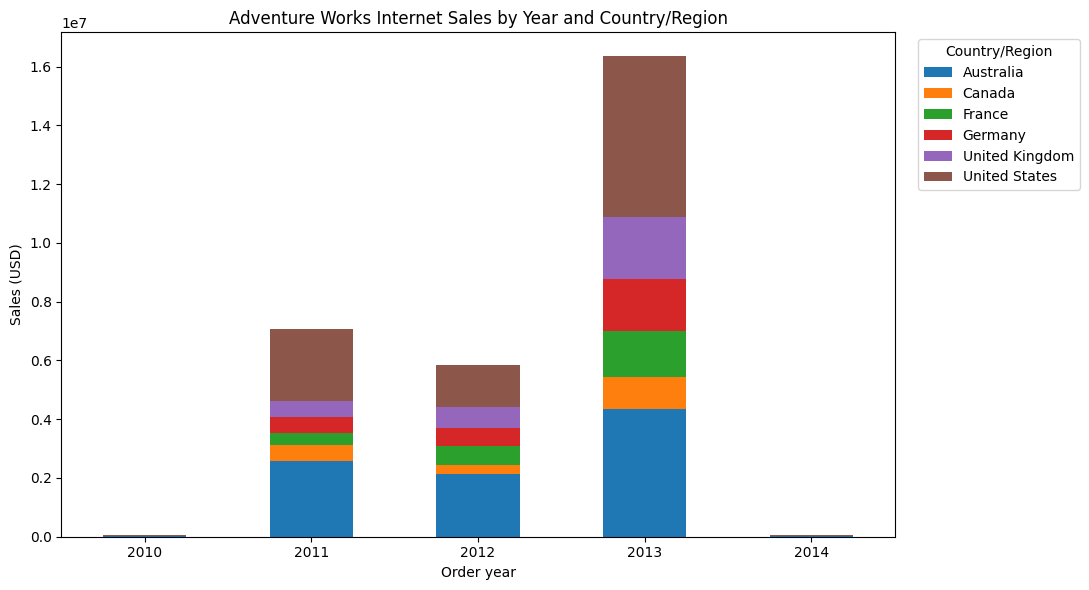

Data coverage (first and last order dates in each year):


,min,max
Year,,
2010,2010-12-29,2010-12-31
2011,2011-01-01,2011-12-31
2012,2012-01-01,2012-12-31
2013,2013-01-01,2013-12-31
2014,2014-01-01,2014-01-28


In [4]:
sales_by_year_region = df.pivot_table(
    index='Year',
    columns='EnglishCountryRegionName',
    values='SalesAmount',
    aggfunc='sum',
    fill_value=0
).sort_index()

print('Q1. Internet sales by year and country/region (USD):')
display(sales_by_year_region.round(2))

print('Total sales by country/region:')
region_totals = df.groupby('EnglishCountryRegionName')['SalesAmount'].sum().sort_values(ascending=False)
display(region_totals.round(2).to_frame('TotalSales'))

ax = sales_by_year_region.plot(kind='bar', stacked=True, figsize=(11, 6))
ax.set(title='Adventure Works Internet Sales by Year and Country/Region',
       xlabel='Order year', ylabel='Sales (USD)')
ax.legend(title='Country/Region', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Caution: 2010 and 2014 do not contain complete annual coverage.
print('Data coverage (first and last order dates in each year):')
display(df.groupby('Year')['OrderDate'].agg(['min', 'max']))

## 4. Question 2 — Income statistics and gender by country/region

In [5]:
customer_info = df.drop_duplicates(subset="CustomerKey")

income_stats = (
    customer_info
    .groupby(["EnglishCountryRegionName", "Gender"])
    ["YearlyIncome"]
    .describe()
)

display(income_stats.round(2))

count      mean       std      min      25%  \
EnglishCountryRegionName Gender                                                 
Australia                F       1777.0  65284.19  31164.36  10000.0  40000.0   
                         M       1814.0  63412.35  32450.71  10000.0  40000.0   
Canada                   F        767.0  56505.87  19181.55  10000.0  40000.0   
                         M        804.0  57798.51  21214.77  10000.0  40000.0   
France                   F        893.0  35341.55  26915.85  10000.0  20000.0   
                         M        917.0  36172.30  27633.45  10000.0  20000.0   
Germany                  F        874.0  43810.07  35715.76  10000.0  20000.0   
                         M        906.0  42108.17  35277.49  10000.0  20000.0   
United Kingdom           F        934.0  52184.15  48288.44  10000.0  20000.0   
                         M        979.0  52155.26  48593.22  10000.0  20000.0   
United States            F       3888.0  63276.75  25166.56  10000.0  40000.0   
                         M       3931.0  63953.19  26228.43  10000.0  40000.0   

                                     50%      75%       max  
EnglishCountryRegionName Gender                              
Australia                F       70000.0  90000.0  160000.0  
                         M       70000.0  80000.0  170000.0  
Canada                   F       60000.0  70000.0  170000.0  
                         M       60000.0  70000.0  170000.0  
France                   F       30000.0  40000.0  110000.0  
                         M       30000.0  40000.0  110000.0  
Germany                  F       30000.0  40000.0  130000.0  
                         M       30000.0  40000.0  130000.0  
United Kingdom           F       30000.0  40000.0  170000.0  
                         M       30000.0  40000.0  170000.0  
United States            F       60000.0  70000.0  170000.0  
                         M       60000.0  70000.0  170000.0

## 5. Product category sales and average price — Question 3

Top Category: Bikes
Average Price: 1862.42


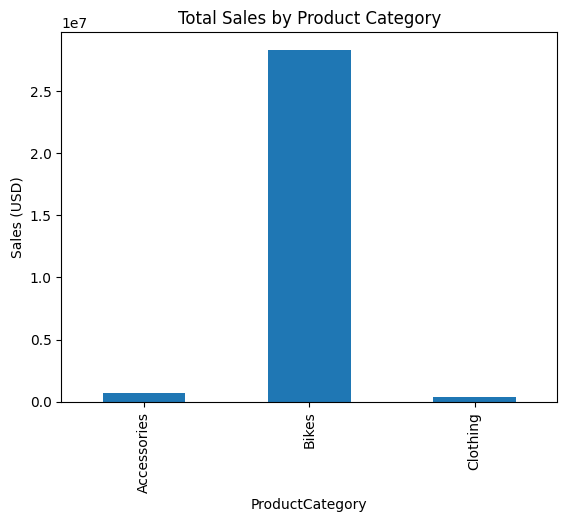

In [6]:
#先根据category汇总salesamount，再排序，再求平均
category_sales = df.groupby("ProductCategory")["SalesAmount"].sum()
top_category = category_sales.idxmax()
# Calculate its average unit price
avg_price = df.loc[
    df["ProductCategory"] == top_category,
    "UnitPrice"
].mean()

print("Top Category:", top_category)
print("Average Price:", round(avg_price, 2))

# Visualization
category_sales.plot(kind="bar")
plt.title("Total Sales by Product Category")
plt.ylabel("Sales (USD)")
plt.show()

## 6. Question 4 — Home ownership and customer-level sales
Does owning a home make a difference in sales? Explain your analysis.

Q4. Customer spending by home ownership:


,CustomerCount,TotalSales,MeanSalesPerCustomer,MedianSalesPerCustomer,MeanOrdersPerCustomer,MeanYearlyIncome
HomeOwnership,,,,,,
Does not own,5982,8973327.42,1500.05,209.96,1.44,55172.18
Owns home,12502,20385349.80,1630.57,342.00,1.52,58326.67


Mean spending difference (owners vs non-owners): +8.70%
Average spending PER CUSTOMER by region and home ownership:


HomeOwnership,Does not own,Owns home
EnglishCountryRegionName,,
Australia,2500.68,2536.09
Canada,1141.96,1316.04
France,1018.62,1699.16
Germany,1272.06,1806.90
United Kingdom,1466.36,1928.59
United States,1213.75,1195.59


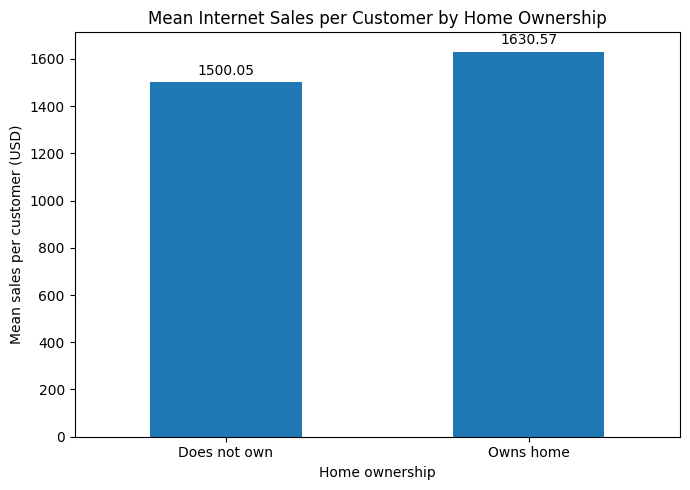

In [9]:
#先按照customerkey把同一个人买的所有商品聚合，再分类这个人有没有房子
# Aggregate sales at CUSTOMER level, not line-item level.
customer_sales = (
    df.groupby('CustomerKey')
    .agg(
        CustomerSales=('SalesAmount', 'sum'),
        Orders=('SalesOrderNumber', 'nunique')
    )
    .reset_index()
)
customers = customer_info.merge(customer_sales, on='CustomerKey', validate='one_to_one')
customers['HomeOwnership'] = customers['HouseOwnerFlag'].map({1: 'Owns home', 0: 'Does not own'})

home_summary = (
    customers.groupby('HomeOwnership')
    .agg(
        CustomerCount=('CustomerKey', 'nunique'),
        TotalSales=('CustomerSales', 'sum'),
        MeanSalesPerCustomer=('CustomerSales', 'mean'),
        MedianSalesPerCustomer=('CustomerSales', 'median'),
        MeanOrdersPerCustomer=('Orders', 'mean'),
        MeanYearlyIncome=('YearlyIncome', 'mean')
    )
)

print('Q4. Customer spending by home ownership:')
display(home_summary.round(2))

owner_mean = home_summary.loc['Owns home', 'MeanSalesPerCustomer']
nonowner_mean = home_summary.loc['Does not own', 'MeanSalesPerCustomer']
difference_pct = (owner_mean / nonowner_mean - 1) * 100
print(f'Mean spending difference (owners vs non-owners): {difference_pct:+.2f}%')

# Descriptive breakdown by region to check for geographic differences
home_by_region = customers.pivot_table(
    index='EnglishCountryRegionName',
    columns='HomeOwnership',
    values='CustomerSales',
    aggfunc='mean'
)
print('Average spending PER CUSTOMER by region and home ownership:')
display(home_by_region.round(2))

ax = home_summary['MeanSalesPerCustomer'].plot(kind='bar', figsize=(7, 5))
ax.set(title='Mean Internet Sales per Customer by Home Ownership',
       xlabel='Home ownership', ylabel='Mean sales per customer (USD)')
ax.bar_label(ax.containers[0,1], fmt='%.2f', padding=3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()